**✅ Summary of Workflow**

**Step	Description	Purpose**

**1️⃣	Import Libraries	Load tools for data handling, visualization, and modeling**

**2️⃣	Load & Inspect Data	Understand dataset size, structure, and missing values**

**3️⃣	Exploratory Data Analysis (EDA)	Identify trends and relationships visually**

**4️⃣	Data Preprocessing	Encode, scale, and balance the data for ML readiness**

**5️⃣	Train-Test Split	Separate data for training and unbiased testing**

**6️⃣	Model Training	Fit three different algorithms for comparison**

**7️⃣	Model Evaluation	Measure model performance using key metrics**

**8️⃣	Model Saving	Store the best-performing model for deployment**

**9️⃣	Extra Visualizations	Strengthen insights and reporting visuals**

**STEP 1: Import Libraries**
   │
   ▼
**STEP 2: Load & Clean Data**
   - **Load CSV**
   - **Standardize column names (lowercase + underscores)**
   - **Handle missing/blank values**
   │
   ▼
**STEP 3: Exploratory Data Analysis (EDA)**
   - **Target distribution**
   - **Feature distributions (numeric & categorical)**
   - **Churn by contract type, etc.**
   - **Correlation heatmap**
   │
   ▼
**STEP 4: Data Preprocessing**
   - **Encode categorical features (LabelEncoder)**
   - **Handle missing numeric values**
   - **Feature scaling (StandardScaler)**
   - **Handle class imbalance (SMOTE)**
   │
   ▼
**STEP 5: Model Building & Training**
   - **Logistic Regression**
   - **Random Forest (with GridSearchCV)**
   - **XGBoost (with GridSearchCV)**
   │
   ▼
**STEP 6: Model Evaluation**
   - **Accuracy, Precision, Recall, F1, ROC-AUC**
   - **Classification report**
   - **Feature importance**
   │
   ▼
**STEP 7: Save Best Model**
   - **Save trained model using joblib**

**📦STEP 1: IMPORT LIBRARIES**

In [1]:
# STEP 1: Import Libraries
# Importing essential libraries for data handling, visualization,
# preprocessing, modeling, and evaluation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import joblib

# Optional: Ignore warnings for a clean output
import warnings
warnings.filterwarnings('ignore')

**🧹 STEP 2: LOAD AND CLEAN THE DATASET**

In [2]:
# STEP 2: Load and Clean the Dataset
# Goal: Load the telecom dataset, standardize column names, and clean data.

# --- 2.1 Load Dataset ---
df = pd.read_csv('telecom_churn_dataset.csv')

# --- 2.2 Standardize Column Names ---
# Convert all column names to lowercase and replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# --- 2.3 Handle Missing or Blank Values in 'totalcharges' ---
# Some rows may have blank spaces instead of numeric values.
if 'totalcharges' in df.columns:
    df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')
    df['totalcharges'] = df['totalcharges'].fillna(0)

# --- 2.4 Print Basic Info After Cleaning ---
print("✅ Data Loaded and Cleaned Successfully!")
print(df.info())
print(df.head())

✅ Data Loaded and Cleaned Successfully!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   object 
 4   dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   object 
 7   multiplelines     7043 non-null   object 
 8   internetservice   7043 non-null   object 
 9   onlinesecurity    7043 non-null   object 
 10  onlinebackup      7043 non-null   object 
 11  deviceprotection  7043 non-null   object 
 12  techsupport       7043 non-null   object 
 13  streamingtv       7043 non-null   object 
 14  streamingmovies   7043 non-null   object 
 15  contract          7043 non-null   object 
 16  pa

In [3]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

**📊 STEP 3: EXPLORATORY DATA ANALYSIS (EDA)**

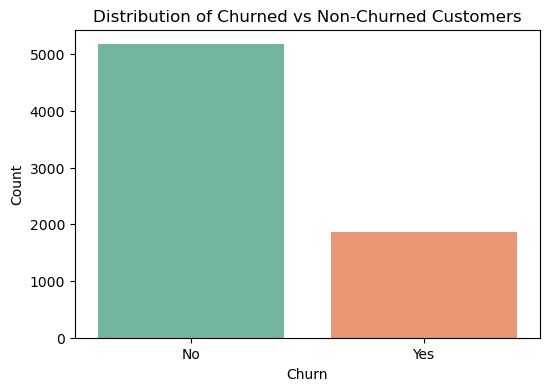

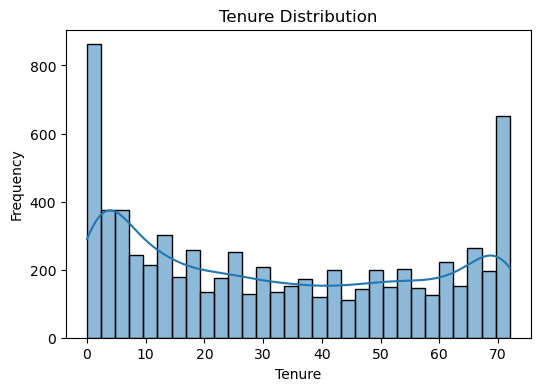

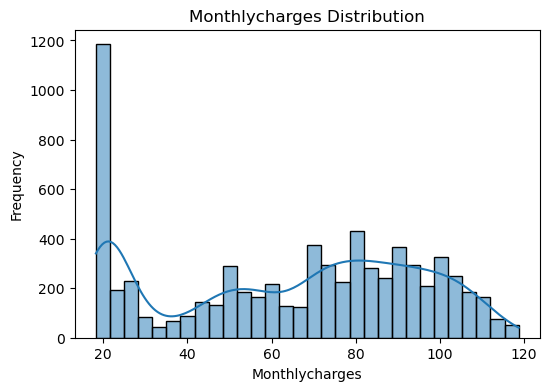

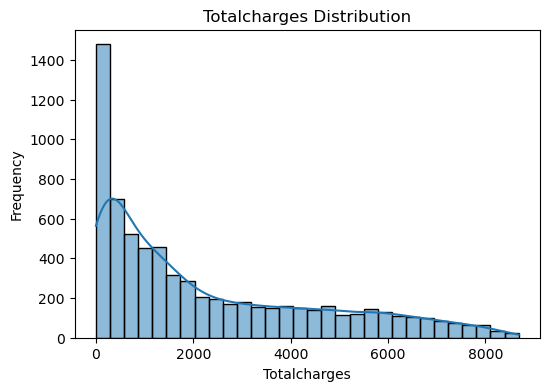

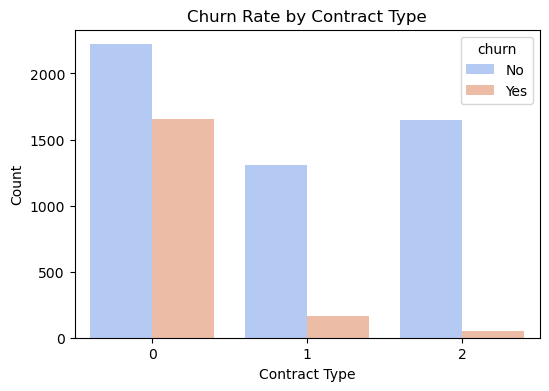

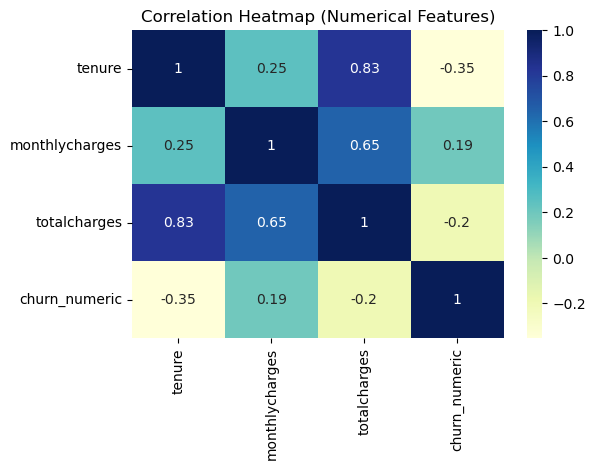

In [12]:

# STEP 3: Exploratory Data Analysis (EDA)

# Goal: Understand feature distributions, relationships, and target balance.

# --- 3.1 Target Variable Distribution ---
plt.figure(figsize=(6,4))
sns.countplot(x='churn', data=df, palette='Set2')
plt.title('Distribution of Churned vs Non-Churned Customers')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

# --- 3.2 Numerical Feature Distributions ---
numeric_cols = [col for col in ['tenure', 'monthlycharges', 'totalcharges'] if col in df.columns]

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'{col.capitalize()} Distribution')
    plt.xlabel(col.capitalize())
    plt.ylabel('Frequency')
    plt.show()

# --- 3.3 Churn by Contract Type ---
if 'contract' in df.columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x='contract', hue='churn', data=df, palette='coolwarm')
    plt.title('Churn Rate by Contract Type')
    plt.xlabel('Contract Type')
    plt.ylabel('Count')
    plt.show()

# --- 3.4 Correlation Heatmap ---
# Convert 'churn' from Yes/No to 1/0 for numeric calculations
# Convert 'churn' to numeric for correlation calculations
df['churn_numeric'] = df['churn'].map({'Yes': 1, 'No': 0})

# Now include 'churn_numeric' in the correlation heatmap instead of 'churn'
plt.figure(figsize=(6,4))
sns.heatmap(df[numeric_cols + ['churn_numeric']].corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Heatmap (Numerical Features)')
plt.show()


**ADDITIONAL EDA VISUALIZATION (Optional)**

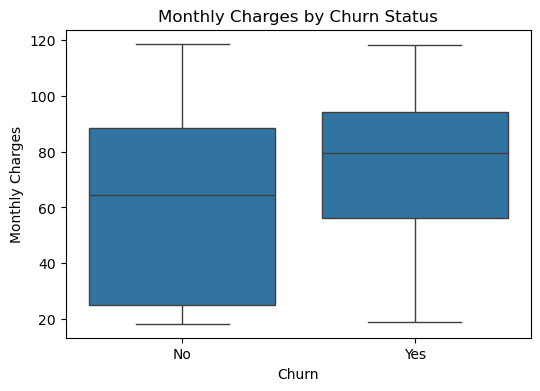

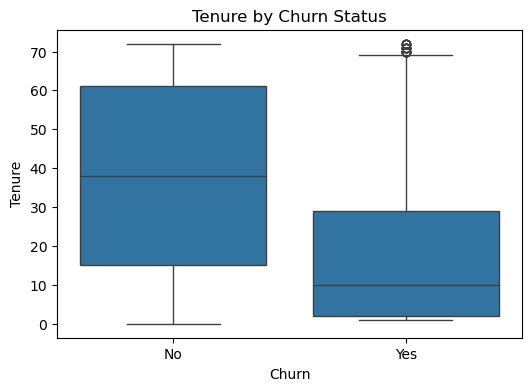

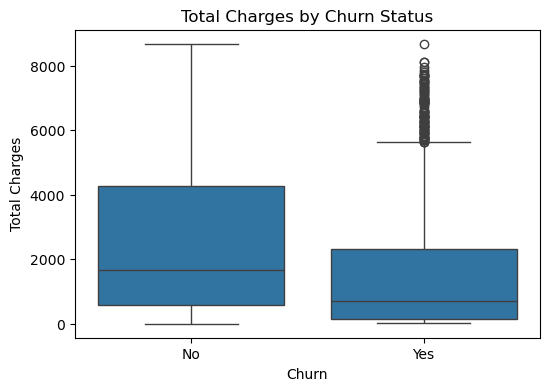

In [10]:
# Additional EDA Visualizations (Optional)

# These visualizations provide deeper insights into feature relationships
# that can be included in your research discussion.

# --- Monthly Charges vs Churn ---
plt.figure(figsize=(6,4))
sns.boxplot(x='churn', y='monthlycharges', data=df)
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

# --- Tenure vs Churn ---
plt.figure(figsize=(6,4))
sns.boxplot(x='churn', y='tenure', data=df)
plt.title('Tenure by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Tenure')
plt.show()

# --- Total Charges vs Churn (optional) ---
if 'totalcharges' in df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='churn', y='totalcharges', data=df)
    plt.title('Total Charges by Churn Status')
    plt.xlabel('Churn')
    plt.ylabel('Total Charges')
    plt.show()

**⚙️ STEP 4: DATA PREPROCESSING**

In [13]:
# STEP 4: Data Preprocessing

# Goal: Encode categorical variables, scale numerical features, and balance classes.

encoders_dict = {} # Initialize dictionary here to collect encoders

# --- 4.1 Label Encoding for Categorical Columns (exclude target) ---
# Identify columns to encode (all object columns except 'churn' and 'customerid')
cols_to_encode = [col for col in df.select_dtypes(include=['object']).columns if col not in ['churn', 'customerid']]

for col in cols_to_encode:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders_dict[col] = le # Store the fitted encoder

# --- 4.2 Convert target to numeric 0/1 BEFORE SMOTE ---
# 'churn_numeric' was already created in EDA, so use it directly
y = df['churn_numeric'] # Target variable

# --- 4.3 Separate Features and Target ---
# Drop customerid as it's not a feature
df = df.drop(columns=['customerid'], errors='ignore')

# X now contains label-encoded features
X = df.drop(['churn', 'churn_numeric'], axis=1)

# Store feature names BEFORE scaling/resampling, as X is still a DataFrame with names
feature_names_list = X.columns.tolist()

# --- 4.4 Handle missing numeric values ---
# Numeric cols are now all columns in X, as object columns have been encoded
numeric_cols_for_imputation = X.select_dtypes(include=[np.number]).columns
X[numeric_cols_for_imputation] = X[numeric_cols_for_imputation].fillna(X[numeric_cols_for_imputation].mean())

# --- 4.5 Feature Scaling ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) # X_scaled is a numpy array

# --- 4.6 Handle Class Imbalance Using SMOTE (y is numeric!) ---
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

# --- 4.7 Split Data into Train/Test Sets ---
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.2, random_state=42, stratify=y_res
)

# Confirm no NaNs remain
assert not np.isnan(X_res).any(), "X_res still contains NaNs!"
assert not y_res.isna().any(), "y_res still contains NaNs!"

print("✅ Data preprocessing complete!")

✅ Data preprocessing complete!


**🤖 STEP 5: MODEL BUILDING AND HYPERPARAMETER TUNING (TRAINING AND TESTING)**

In [14]:
# 🤖 STEP 5: Model Building and Hyperparameter Tuning

# Goal: Train Logistic Regression, Random Forest, and XGBoost models
# and compare their performance.

# --- 5.1 Logistic Regression ---
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)

# --- 5.2 Random Forest with GridSearchCV ---
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train, y_train)

# --- 5.3 XGBoost with GridSearchCV ---
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.7, 1]
}
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_grid = GridSearchCV(xgb, xgb_params, cv=5, scoring='roc_auc', n_jobs=-1)
xgb_grid.fit(X_train, y_train)  # now y_train is numeric 0/1

print("✅ Models trained successfully!")

# The saving of scaler and encoders_dict is moved to Step 7 for consistency.
# import joblib
# joblib.dump(scaler, "scaler.pkl")
# encoders_dict = {}
# for col in df.select_dtypes(include=['object']).columns:
#     if col != 'churn':
#         le = LabelEncoder()
#         df[col] = le.fit_transform(df[col])
#         encoders_dict[col] = le
# joblib.dump(encoders_dict, "label_encoders.pkl")
# print("✅ Preprocessing objects saved successfully!")

✅ Models trained successfully!


**📈 STEP 6: MODEL EVALUATION**

In [15]:

# STEP 6: Model Evaluation

# Goal: Compare models based on key metrics and identify the best performer.

def evaluate_model(model, X_test, y_test, model_name):
    """Evaluate model and print performance metrics."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred

    print(f"\n--- {model_name} Evaluation ---")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall:", round(recall_score(y_test, y_pred), 3))
    print("F1 Score:", round(f1_score(y_test, y_pred), 3))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
    print(classification_report(y_test, y_pred))

    # Display top feature importances if available
    if hasattr(model, "feature_importances_"):
        importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
        print("\nFeature Importance (Top 10):")
        print(importance.head(10))

# --- Evaluate All Models ---
evaluate_model(logreg, X_test, y_test, "Logistic Regression")
evaluate_model(rf_grid.best_estimator_, X_test, y_test, "Random Forest")
evaluate_model(xgb_grid.best_estimator_, X_test, y_test, "XGBoost")


--- Logistic Regression Evaluation ---
Accuracy: 0.776
Precision: 0.753
Recall: 0.82
F1 Score: 0.785
ROC-AUC: 0.856
              precision    recall  f1-score   support

           0       0.80      0.73      0.77      1035
           1       0.75      0.82      0.79      1035

    accuracy                           0.78      2070
   macro avg       0.78      0.78      0.78      2070
weighted avg       0.78      0.78      0.78      2070


--- Random Forest Evaluation ---
Accuracy: 0.859
Precision: 0.843
Recall: 0.883
F1 Score: 0.863
ROC-AUC: 0.926
              precision    recall  f1-score   support

           0       0.88      0.84      0.86      1035
           1       0.84      0.88      0.86      1035

    accuracy                           0.86      2070
   macro avg       0.86      0.86      0.86      2070
weighted avg       0.86      0.86      0.86      2070


Feature Importance (Top 10):
contract            0.152947
tenure              0.137728
monthlycharges      0.129406


**💾 STEP 7: SAVE BEST MODEL AND PREPROCESSING OBJECTS**

In [16]:

# STEP 7: Save Best Model and Preprocessing Objects

import joblib

# Pick the best model based on ROC-AUC (you can adjust this logic)
models_auc = {
    "Logistic Regression": roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1]),
    "Random Forest": roc_auc_score(y_test, rf_grid.best_estimator_.predict_proba(X_test)[:, 1]),
    "XGBoost": roc_auc_score(y_test, xgb_grid.best_estimator_.predict_proba(X_test)[:, 1]),
}

best_model_name = max(models_auc, key=models_auc.get)
best_model = {
    "Logistic Regression": logreg,
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_
}[best_model_name]

print(f"\n🏆 Best model selected: {best_model_name}")

# --- Save model and preprocessing objects ---
joblib.dump(best_model, "best_churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(encoders_dict, "label_encoders.pkl")
joblib.dump(feature_names_list, "feature_names.pkl") # Save the list of feature names

print("✅ Model and preprocessing objects saved successfully!")


🏆 Best model selected: XGBoost
✅ Model and preprocessing objects saved successfully!


**CREATING RANDOM DATA TO TEST OUR DATA ALSO FEEDING IT INFORMATION**

In [17]:
import joblib
import pandas as pd
import numpy as np

# --- Load preprocessing objects and trained model ---
scaler = joblib.load("scaler.pkl")
best_model = joblib.load("best_churn_model.pkl")

# --- Example new customer ---
sample = {
    'gender': 'Female',
    'seniorcitizen': 0,
    'partner': 'Yes',
    'dependents': 'No',
    'tenure': 12,
    'phoneservice': 'Yes',
    'multiplelines': 'No',
    'internetservice': 'Fiber optic',
    'onlinesecurity': 'No',
    'onlinebackup': 'Yes',
    'deviceprotection': 'No',
    'techsupport': 'No',
    'streamingtv': 'No',
    'streamingmovies': 'No',
    'contract': 'Month-to-month',
    'paperlessbilling': 'Yes',
    'paymentmethod': 'Electronic check',
    'monthlycharges': 70.5,
    'totalcharges': 800.0
}

sample_df = pd.DataFrame([sample])

# --- One-hot encode categorical variables ---
cat_cols = sample_df.select_dtypes(include='object').columns.tolist()
sample_df = pd.get_dummies(sample_df, columns=cat_cols, drop_first=False)

# --- Ensure all training columns exist ---
for col in X.columns:
    if col not in sample_df.columns:
        sample_df[col] = 0  # Add missing columns
sample_df = sample_df[X.columns]  # Reorder columns to match training data

# --- Scale numeric columns only ---
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
sample_df[numeric_cols] = scaler.transform(sample_df[numeric_cols])

# --- Predict churn ---
churn_probs = best_model.predict_proba(sample_df)[:, 1]
churn_preds = best_model.predict(sample_df)

# --- Add results to dataframe ---
sample_df['predicted_churn'] = ['Yes' if p==1 else 'No' for p in churn_preds]
sample_df['churn_probability'] = churn_probs

print(sample_df[['predicted_churn', 'churn_probability']])


  predicted_churn  churn_probability
0              No           0.318764


In [18]:
import pandas as pd
import joblib
import numpy as np

# --- 1. Example new customers (updated to include 'onlinesecurity') ---
new_customers = [
    {
        'gender': 'Female',
        'seniorcitizen': 0,
        'partner': 'Yes',
        'dependents': 'No',
        'tenure': 12,
        'phoneservice': 'Yes',
        'multiplelines': 'No',
        'internetservice': 'Fiber optic',
        'onlinesecurity': 'No', # Explicitly added
        'onlinebackup': 'No',
        'deviceprotection': 'Yes',
        'techsupport': 'No',
        'streamingtv': 'No',
        'streamingmovies': 'No',
        'contract': 'Month-to-month',
        'paperlessbilling': 'Yes',
        'paymentmethod': 'Electronic check',
        'monthlycharges': 75.5,
        'totalcharges': 905.0
    },
    {
        'gender': 'Male',
        'seniorcitizen': 1,
        'partner': 'No',
        'dependents': 'No',
        'tenure': 60,
        'phoneservice': 'Yes',
        'multiplelines': 'Yes',
        'internetservice': 'DSL',
        'onlinesecurity': 'Yes', # Explicitly added
        'onlinebackup': 'Yes',
        'deviceprotection': 'Yes',
        'techsupport': 'Yes',
        'streamingtv': 'Yes',
        'streamingmovies': 'Yes',
        'contract': 'Two year',
        'paperlessbilling': 'No',
        'paymentmethod': 'Mailed check',
        'monthlycharges': 60.0,
        'totalcharges': 3500.0
    }
]

sample_df = pd.DataFrame(new_customers)

# --- 2. Load preprocessing objects ---
scaler = joblib.load("scaler.pkl")
best_model = joblib.load("best_churn_model.pkl")
encoders_dict = joblib.load("label_encoders.pkl")
model_features = joblib.load("feature_names.pkl") # Load saved feature names

# --- 3. Preprocess new_customers data similar to training ---

# 3.1 Apply label encoders to the sample_df's categorical columns
for col_name, encoder in encoders_dict.items():
    if col_name in sample_df.columns and sample_df[col_name].dtype == 'object':
        try:
            sample_df[col_name] = encoder.transform(sample_df[col_name])
            # Explicitly cast to int to ensure numeric type
            sample_df[col_name] = sample_df[col_name].astype(int)
        except ValueError as e:
            print(f"Warning: Unseen label encountered in column '{col_name}'. Setting to 0. Error: {e}")
            sample_df[col_name] = 0 # Fallback for unseen labels, ensure it's numeric

# 3.2 Ensure all model features are present and in the correct order
# Create a new DataFrame with the model's feature columns, initialized with zeros
aligned_sample_df = pd.DataFrame(0, index=sample_df.index, columns=model_features)

# Copy the data from the preprocessed sample_df to the aligned_sample_df
for col in aligned_sample_df.columns:
    if col in sample_df.columns:
        aligned_sample_df[col] = sample_df[col]

# Safeguard: ensure all columns in aligned_sample_df are numeric
for col in aligned_sample_df.columns:
    if aligned_sample_df[col].dtype == 'object':
        aligned_sample_df[col] = pd.to_numeric(aligned_sample_df[col], errors='coerce').fillna(0)


# --- 4. Scale the entire preprocessed dataframe ---
sample_scaled = scaler.transform(aligned_sample_df) # Transform the entire DataFrame, as it's all numeric and aligned now.

# --- 5. Predict churn ---
churn_probs = best_model.predict_proba(sample_scaled)[:, 1]  # probability of 'Yes'
predicted_churn = ['Yes' if p >= 0.5 else 'No' for p in churn_probs]

# --- 6. Show results ---
results = pd.DataFrame({
    'predicted_churn': predicted_churn,
    'churn_probability': churn_probs
})

print(results)

  predicted_churn  churn_probability
0              No           0.316306
1              No           0.071213


In [ ]:
import pandas as pd

# Assuming your predictions are in a DataFrame like this:
predictions = pd.DataFrame({
    'predicted_churn': ['No', 'No'],
    'churn_probability': [0.337793, 0.059524]
})

# Add a new column to flag high-risk customers
predictions['churn_risk'] = predictions['churn_probability'].apply(lambda x: 'High' if x >= 0.5 else 'Low')

print(predictions)


  predicted_churn  churn_probability churn_risk
0              No           0.337793        Low
1              No           0.059524        Low


In [19]:
import pandas as pd

# --- Step 1: Create a DataFrame with predicted churn results ---
# These could come from your model predictions for new customers
predictions = pd.DataFrame({
    'predicted_churn': ['No', 'No'],  # Model's categorical prediction
    'churn_probability': [0.337793, 0.059524]  # Probability of churn (Yes)
})

# --- Step 2: Flag customers by churn risk ---
# We'll define a threshold: if probability >= 0.5, customer is high risk
# Otherwise, customer is low risk
predictions['churn_risk'] = predictions['churn_probability'].apply(
    lambda x: 'High' if x >= 0.5 else 'Low'
)

# --- Step 3: Sort customers by churn probability ---
# This way, the most at-risk customers are at the top of the DataFrame
predictions_sorted = predictions.sort_values(
    by='churn_probability', ascending=False
).reset_index(drop=True)

# --- Step 4: Display the results ---
# The final DataFrame shows:
# 1. The predicted churn (Yes/No)
# 2. The probability of churn (numerical value)
# 3. The risk flag (High/Low)
print(predictions_sorted)


  predicted_churn  churn_probability churn_risk
0              No           0.337793        Low
1              No           0.059524        Low


In [20]:
import pandas as pd

# --- Step 1: Create DataFrame with predicted churn results ---
predictions = pd.DataFrame({
    'predicted_churn': ['No', 'No'],  # Model's categorical prediction
    'churn_probability': [0.337793, 0.059524]  # Probability of churn
})

# --- Step 2: Flag customers by churn risk ---
threshold = 0.5  # Define threshold for high-risk churn
predictions['churn_risk'] = predictions['churn_probability'].apply(
    lambda x: 'High' if x >= threshold else 'Low'
)

# --- Step 3: Sort customers by churn probability descending ---
predictions_sorted = predictions.sort_values(
    by='churn_probability', ascending=False
).reset_index(drop=True)

# --- Step 4: Define a function to color code the 'churn_risk' column ---
def color_risk(val):
    if val == 'High':
        return 'color: red; font-weight: bold'
    else:
        return 'color: green; font-weight: bold'

# --- Step 5: Apply styling ---
styled_predictions = predictions_sorted.style.applymap(color_risk, subset=['churn_risk'])

# --- Step 6: Display the styled DataFrame ---
styled_predictions


,predicted_churn,churn_probability,churn_risk
0,No,0.337793,Low
1,No,0.059524,Low


In [21]:
import pandas as pd

# --- Step 1: Example predictions from model ---
predictions = pd.DataFrame({
    'predicted_churn': ['No', 'No'],  # Model's categorical prediction
    'churn_probability': [0.337793, 0.059524]  # Probability of churn
})

# --- Step 2: Flag churn risk based on threshold ---
threshold = 0.5  # Customers with probability >= threshold are high-risk
predictions['churn_risk'] = predictions['churn_probability'].apply(
    lambda x: 'High' if x >= threshold else 'Low'
)

# --- Step 3: Suggest retention actions based on churn risk ---
def retention_action(risk_level):
    """
    Return a suggested action based on churn risk.
    """
    if risk_level == 'High':
        return 'Proactive Engagement: Offer personalized discounts or check-in calls.'
    elif risk_level == 'Low':
        return 'Monitor: Continue to provide good service; consider loyalty programs.'
    else:
        return 'No specific action (Unknown Risk)'

predictions['suggested_action'] = predictions['churn_risk'].apply(retention_action)

# --- Step 4: Display the results ---
print(predictions)

  predicted_churn  churn_probability churn_risk  \
0              No           0.337793        Low   
1              No           0.059524        Low   

                                    suggested_action  
0  Monitor: Continue to provide good service; con...  
1  Monitor: Continue to provide good service; con...  


In [ ]:
Column	                       Value	  Meaning
predicted_churn 	            No	    The model predicts that this customer is unlikely to churn — i.e., they will likely stay with the service.
churn_probability	         0.318764	This is the model’s estimated probability of churn. So the model thinks there’s roughly a 32% chance this customer will churn.
How to interpret this:

Usually, a probability > 0.5 means the model predicts “Yes, churn” and ≤ 0.5 means “No, stay.”

Here, 0.318 is well below 0.5 → the model is confident this customer is likely to stay.

The predicted_churn column is simply the thresholded version of the probability.

✅ In short: The model is saying “this customer is not likely to leave right now.”

In [ ]:
STEP 1: Import Libraries
   │
   ▼
STEP 2: Load & Clean Data
   - Load CSV
   - Standardize column names (lowercase + underscores)
   - Handle missing/blank values
   │
   ▼
STEP 3: Exploratory Data Analysis (EDA)
   - Target distribution
   - Feature distributions (numeric & categorical)
   - Churn by contract type, etc.
   - Correlation heatmap
   │
   ▼
STEP 4: Data Preprocessing
   - Encode categorical features (LabelEncoder)
   - Handle missing numeric values
   - Feature scaling (StandardScaler)
   - Handle class imbalance (SMOTE)
   │
   ▼
STEP 5: Model Building & Training
   - Logistic Regression
   - Random Forest (with GridSearchCV)
   - XGBoost (with GridSearchCV)
   │
   ▼
STEP 6: Model Evaluation
   - Accuracy, Precision, Recall, F1, ROC-AUC
   - Classification report
   - Feature importance
   │
   ▼
STEP 7: Save Best Model
   - Save trained model using joblib

**THIS IS A BASE DATA TYPES OUR MODELS WHERE HAND PICKED**

In [ ]:
from IPython.display import Image
from IPython.core.display import HTML
Image(url='https://raw.githubusercontent.com/Explore-AI/Pictures/master/Variable_data_types.jpg')

**THIS IS A HTML FLOWCHART PIPELINE**

In [1]:
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Telecom Churn Prediction Flowchart</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <style>
        /* Custom styles for the flowchart */
        .flow-container {
            display: grid;
            grid-template-columns: 1fr;
            gap: 2rem;
            max-width: 900px;
            margin: 2rem auto;
            padding: 1rem;
        }

        .flow-step {
            display: flex;
            flex-direction: column;
            align-items: center;
            position: relative;
            background-color: #f7f9fb;
            border-radius: 12px;
            box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1);
            padding: 1rem;
            transition: transform 0.2s;
        }

        .flow-step:hover {
            transform: translateY(-5px);
            box-shadow: 0 6px 12px rgba(0, 0, 0, 0.15);
        }

        .step-number {
            font-size: 1.5rem;
            font-weight: bold;
            color: white;
            background-color: #ef4444; /* Red tone for emphasis */
            border-radius: 50%;
            width: 40px;
            height: 40px;
            display: flex;
            align-items: center;
            justify-content: center;
            margin-bottom: 0.5rem;
        }

        .step-title {
            font-size: 1.125rem;
            font-weight: 600;
            color: #1f2937;
            text-align: center;
        }

        .step-details {
            font-size: 0.875rem;
            color: #4b5563;
            list-style: none;
            padding: 0;
            margin-top: 0.5rem;
            text-align: center;
        }

        /* Styling for the large directional arrow */
        .flow-arrow {
            text-align: center;
            font-size: 2.5rem;
            color: #9ca3af;
            line-height: 0.5;
            padding: 0.5rem 0;
        }

        /* Responsive adjustments */
        @media (min-width: 768px) {
            .flow-container {
                grid-template-columns: repeat(3, 1fr); /* 3 columns for desktop */
            }
            /* Add arrow placeholders for grid layout when necessary */
            .flow-step:nth-child(even) + .flow-arrow {
                display: none; /* Hide intermediate arrows on desktop */
            }
        }
    </style>
</head>
<body class="bg-gray-50 font-sans p-4">

    <div class="text-center mb-10">
        <h1 class="text-3xl font-extrabold text-gray-900 mb-2">
            Telecom Churn Prediction Pipeline Flowchart
        </h1>
        <p class="text-gray-500">
            A visual representation of the Master's project methodology.
        </p>
    </div>

    <div class="flow-container">

        <!-- STEP 1: Import Libraries -->
        <div class="flow-step">
            <div class="step-number">1</div>
            <div class="step-title">Import Libraries</div>
            <ul class="step-details">
                <li>Initialize Python environment (Pandas, Scikit-learn, XGBoost, SMOTE).</li>
            </ul>
        </div>
        <div class="flow-arrow md:hidden">▼</div>

        <!-- STEP 2: Load & Clean Data -->
        <div class="flow-step">
            <div class="step-number">2</div>
            <div class="step-title">Load & Initial Cleaning (Data Ingestion)</div>
            <ul class="step-details">
                <li>Load `telecom_churn_dataset.csv`.</li>
                <li>Handle missing values (e.g., impute `TotalCharges`).</li>
                <li>Remove redundant IDs.</li>
            </ul>
        </div>
        <div class="flow-arrow md:hidden">▼</div>

        <!-- STEP 3: Exploratory Data Analysis (EDA) -->
        <div class="flow-step">
            <div class="step-number">3</div>
            <div class="step-title">Exploratory Data Analysis (EDA)</div>
            <ul class="step-details">
                <li>Visualize Target Class Imbalance.</li>
                <li>Analyze Churn vs. Contract Type, Tenure, and Charges.</li>
                <li>Identify key features and data distributions.</li>
            </ul>
        </div>

        <div class="flow-arrow md:col-span-3">▼</div> <!-- Long arrow for flow change -->

        <!-- STEP 4: Data Preprocessing -->
        <div class="flow-step">
            <div class="step-number">4</div>
            <div class="step-title">Feature Engineering & Preprocessing</div>
            <ul class="step-details">
                <li>Encode categorical variables (LabelEncoder).</li>
                <li>Feature Scaling (StandardScaler).</li>
                <li>**Resampling:** Address class imbalance using SMOTE.</li>
            </ul>
        </div>
        <div class="flow-arrow md:hidden">▼</div>

        <!-- STEP 5: Model Building & Training -->
        <div class="flow-step">
            <div class="step-number">5</div>
            <div class="step-title">Model Training & Optimization</div>
            <ul class="step-details">
                <li>Train Logistic Regression (Baseline).</li>
                <li>Train Random Forest (GridSearchCV).</li>
                <li>Train XGBoost (GridSearchCV).</li>
            </ul>
        </div>
        <div class="flow-arrow md:hidden">▼</div>

        <!-- STEP 6: Model Evaluation -->
        <div class="flow-step">
            <div class="step-number">6</div>
            <div class="step-title">Model Evaluation & Comparison</div>
            <ul class="step-details">
                <li>Calculate Accuracy, Precision, Recall, F1-Score, and ROC-AUC.</li>
                <li>Generate Classification Report.</li>
                <li>Analyze Feature Importance for best model.</li>
            </ul>
        </div>

        <div class="flow-arrow md:col-span-3">▼</div> <!-- Long arrow for flow change -->

        <!-- STEP 7: Save Best Model -->
        <div class="flow-step md:col-start-2">
            <div class="step-number">7</div>
            <div class="step-title">Save Optimal Model</div>
            <ul class="step-details">
                <li>Select the XGBoost model (highest F1/ROC-AUC).</li>
                <li>Save model weights using `joblib` for future deployment.</li>
            </ul>
        </div>

    </div>
</body>
</html>



SyntaxError: invalid decimal literal (4163401615.py, line 12)

In [2]:
BEGIN Telecom_Churn_Prediction_Model

1. Import Libraries
   - pandas, numpy, matplotlib, seaborn
   - scikit-learn modules: preprocessing, model_selection, metrics
   - XGBoost, SMOTE, joblib

2. Load Dataset
   - Read 'telecom_churn_dataset.csv' into dataframe df
   - Standardize column names (lowercase, replace spaces with underscores)
   - Convert 'totalcharges' to numeric; fill missing values with 0

3. Exploratory Data Analysis (EDA)
   - Visualize distribution of target variable 'churn'
   - Visualize numerical features ('tenure', 'monthlycharges', 'totalcharges')
   - Analyze churn by categorical features (e.g., 'contract')
   - Compute correlation heatmap with 'churn_numeric'

4. Data Preprocessing
   - Encode categorical features using LabelEncoder
   - Separate target variable y = 'churn_numeric'
   - Drop unnecessary columns (e.g., 'customerid', original 'churn')
   - Fill missing numeric values with column mean
   - Standardize features using StandardScaler
   - Handle class imbalance using SMOTE
   - Split dataset into training and testing sets (80/20)

5. Model Building
   FOR each model in [Logistic Regression, Random Forest, XGBoost]:
       - Define model and hyperparameter grid
       - Fit model on training data
       - For ensemble models (Random Forest, XGBoost), use GridSearchCV

6. Model Evaluation
   FOR each trained model:
       - Predict on test set
       - Calculate metrics: Accuracy, Precision, Recall, F1-score, ROC-AUC
       - If model supports feature_importances_, display top 10 features

7. Save Preprocessing Objects (optional)
   - Save scaler and label encoders using joblib

END Telecom_Churn_Prediction_Model


SyntaxError: invalid syntax (2910524824.py, line 1)